<font size=7 color="#5499C7" >Assignment 3: CNN</font>
- <font size=5>__Group Members__ : Kourosh Sajjadi - Kasra Noorbakhsh</font>
- <font size=5>__Student IDs__  : 810100587 - 810100230</font> 
- <font size=5>__Course__ : Computer Vision</font> 

<!DOCTYPE html>
<html>
<head>
<style>
  body {
    background: #0f172a;
    color: #e5e7eb;
    font-family: Inter, sans-serif;
  }
  .assignment {
    max-width: 900px;
    margin: auto;
    padding: 20px;
    background: #1f2937;
    border-radius: 12px;
    border: 1px solid #374151;
  }
  h1 {
    color: #22d3ee;
  }
  h2 {
    border-left: 4px solid #22d3ee;
    padding-left: 8px;
  }
  table {
    width: 100%;
    border-collapse: collapse;
    margin-top: 12px;
  }
  th, td {
    border: 1px solid #374151;
    padding: 8px;
    text-align: left;
  }
  th {
    background: #111827;
  }
</style>
</head>
<body>
<div class="assignment">
  <h1>Computer Vision Assignment</h1>
  <p><strong>Course:</strong> Computer Vision<br>
     <strong>Total Points:</strong> 100</p>

  <h2>Objective</h2>
  <ol>
    <li>Use pretrained CNNs for classification, detection, segmentation</li>
    <li>Perform preprocessing</li>
    <li>Run inference on input images</li>
    <li>Evaluate results</li>
  </ol>

  <h2>Grading Breakdown</h2>
  <table>
    <tr><th>Criterion</th><th>Description</th><th>Points</th></tr>
    <tr><td>Correct preprocessing</td><td>Resizing, normalization, tensor conversion</td><td>20</td></tr>
    <tr><td>Correct model usage</td><td>Proper pretrained model inference</td><td>20</td></tr>
    <tr><td>Visualization quality</td><td>Clear side-by-side figures</td><td>20</td></tr>
    <tr><td>Analysis and discussion</td><td>Interpretation and insights</td><td>40</td></tr>
    <tr><td colspan="2"><strong>Total</strong></td><td><strong>100</strong></td></tr>
  </table>

</div>
</body>
</html>

In [1]:
import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path(".matplotlib")))
Path(os.environ["MPLCONFIGDIR"]).mkdir(exist_ok=True)

import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt

import torchvision.transforms as T
import matplotlib.patches as patches
from PIL import Image, ImageOps
from torchvision.models import efficientnet_b4, EfficientNet_B4_Weights
from torchvision.models.segmentation import deeplabv3_resnet50, DeepLabV3_ResNet50_Weights
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights

if torch.backends.mps.is_available():
    device = torch.device('mps')
elif torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

print(f"Using device: {device}")

Using device: cpu


<font size=7 color="#5499C7">1. Show All Input Images</font>

Plot all the images in a single figure.

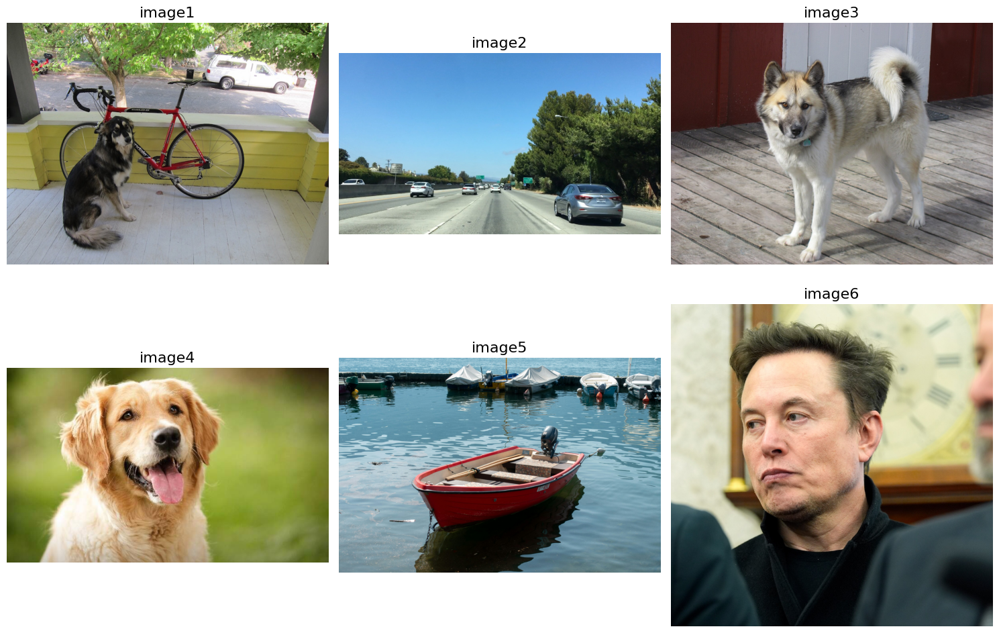

In [2]:
images_dir = Path("Images")
image_paths = sorted(images_dir.glob("image*.jpg"))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, path in zip(axes.flat, image_paths):
    img = Image.open(path).convert("RGB")
    ax.imshow(img)
    ax.set_title(path.name[:-4], fontsize=16)
    ax.axis("off")

plt.tight_layout()
plt.show()

<font size=7 color="#5499C7">2. Task 1 – Image Classification</font>

<font size=5>
In this task, we used pretrained <b>EfficientNet-B4</b> model from torchvision/timm with 1000 classes.
</font>

<font size=6 color="#5499C7">Model Architecture (EfficientNet-B4):</font>
<font size=5>

**EfficientNet-B4** is a state-of-the-art convolutional neural network that achieves superior accuracy with fewer parameters through **compound scaling**.

*   **Compound Scaling:** Simultaneously balances network depth, width, and input resolution using a fixed scaling coefficient.
*   **MBConv Blocks:** Mobile Inverted Bottleneck Convolution blocks with expansion layers, depthwise convolutions, and squeeze-and-excitation (SE) attention mechanisms.
*   **Swish Activation:** Uses Swish (x·sigmoid(x)) instead of ReLU for better gradient flow and improved performance.
*   **Training Dataset:** ImageNet-1K (1.28 million training images, 1,000 object categories).
</font>

<font size=6 color="#5499C7">12-Step Preprocessing Pipeline</font>
<font size=5>

Each step serves a specific purpose in preparing real-world images for robust classification:

1.  **Convert to NumPy (BGR):** Enables powerful OpenCV operations for contrast enhancement.
2.  **Gaussian Blur:** Reduces high-frequency noise from camera sensors.
3.  **Unsharp Masking:** Enhances edges and fine details by subtracting the blurred version.
4.  **CLAHE:** Improves local contrast adaptively across different regions.
5.  **Convert back to PIL:** Returns to PIL format for torchvision compatibility.
6.  **Pad to Square:** Preserves aspect ratio by adding borders rather than distorting.
7.  **Resize with LANCZOS:** High-quality antialiasing filter prevents aliasing artifacts.
8.  **Random Rotation:** Data augmentation for robustness to orientation variations.
9.  **Color Jitter & Grayscale:** Simulates lighting variations and desaturation.
10. **Convert to Tensor:** Transforms to PyTorch tensor format [C, H, W] in [0, 1] range.
11. **ImageNet Normalization:** Standardizes input using ImageNet mean and std.
12. **Add Batch Dimension:** Adds batch axis [1, C, H, W] as required by the model.
</font>

Downloading: "https://download.pytorch.org/models/efficientnet_b4_rwightman-23ab8bcd.pth" to C:\Users\Kasra/.cache\torch\hub\checkpoints\efficientnet_b4_rwightman-23ab8bcd.pth
100%|██████████| 74.5M/74.5M [00:16<00:00, 4.67MB/s]


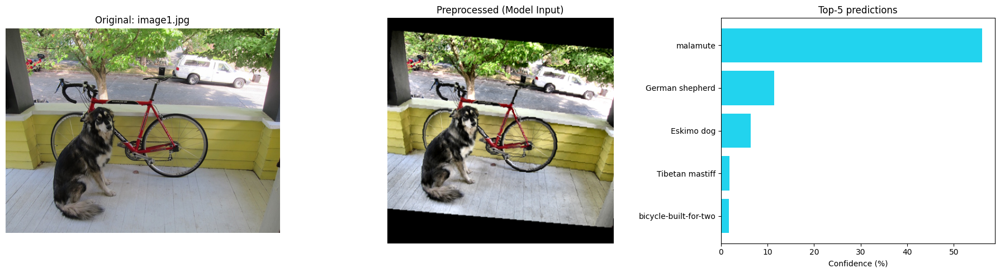

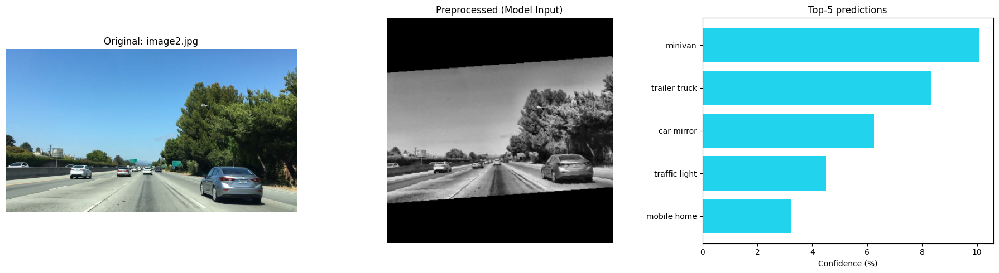

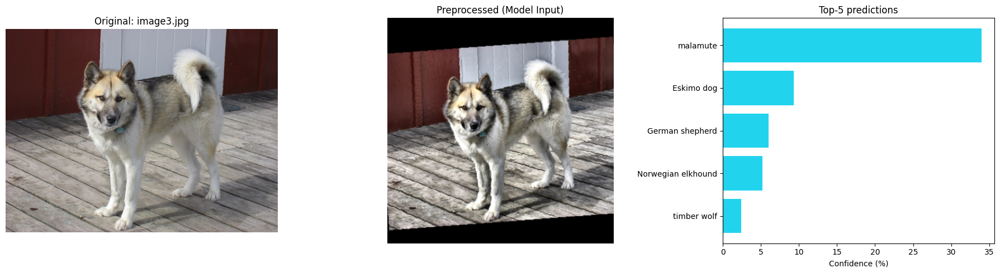

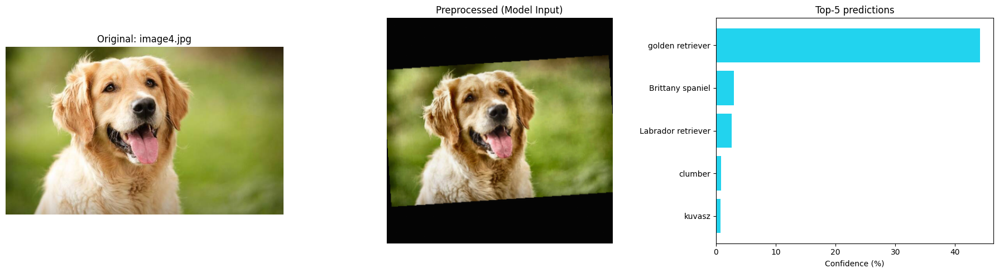

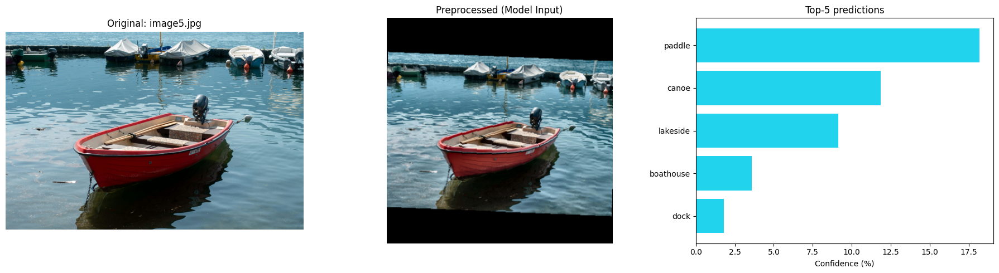

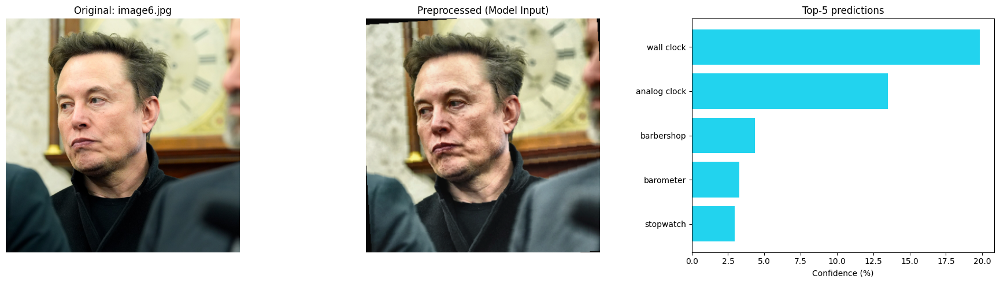

In [3]:
# Load model once
class_weights = EfficientNet_B4_Weights.IMAGENET1K_V1
class_model = efficientnet_b4(weights=class_weights)
class_model.eval().to(device)

imagenet_classes = class_weights.meta["categories"]

def preprocessing(img: Image.Image) -> torch.Tensor:
    """
    12-step preprocessing.
    Returns: tensor ready for EfficientNet-B4
    """
    # 1. Convert to NumPy (BGR) for OpenCV ops
    np_bgr = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGR)

    # 2. Gaussian blur to suppress sensor noise
    blurred = cv2.GaussianBlur(np_bgr, (3, 3), 0)

    # 3. Unsharp masking (sharpen edges)
    sharpened = cv2.addWeighted(np_bgr, 1.5, blurred, -0.5, 0)

    # 4. CLAHE on L channel to boost local contrast
    lab = cv2.cvtColor(sharpened, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    l = clahe.apply(l)
    lab = cv2.merge((l, a, b))
    enhanced_bgr = cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

    # 5. Back to PIL (RGB)
    pil_img = Image.fromarray(cv2.cvtColor(enhanced_bgr, cv2.COLOR_BGR2RGB))

    # 6. Pad to square while preserving aspect ratio
    w, h = pil_img.size
    side = max(w, h)
    pad_left = (side - w) // 2
    pad_top = (side - h) // 2
    pad_right = side - w - pad_left
    pad_bottom = side - h - pad_top
    padded = ImageOps.expand(pil_img, border=(pad_left, pad_top, pad_right, pad_bottom), fill=0)

    # 7. High-quality resize to EfficientNet-B4 input
    resized = padded.resize((380, 380), Image.Resampling.LANCZOS)

    # 8. Mild random rotation for robustness
    rotated = T.RandomRotation(degrees=5)(resized)

    # 9. Random crop + color jitter + grayscale to handle variation
    cropped = T.RandomResizedCrop(size=380, scale=(0.9, 1.0), ratio=(0.95, 1.05))(rotated)
    jittered = T.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02)(cropped)
    color_aug = T.RandomGrayscale(p=0.1)(jittered)

    # 10. To tensor
    tensor = T.ToTensor()(color_aug)

    # 11. Normalize with ImageNet stats
    normalized = T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])(tensor)

    # 12. Add batch dimension
    return normalized.unsqueeze(0)

def classify_and_plot(paths):
    for path in paths:
        img = Image.open(path).convert("RGB")

        # Get preprocessed tensor (keep on CPU for visualization first)
        input_tensor = preprocessing(img)

        # Run inference
        with torch.no_grad():
            logits = class_model(input_tensor.to(device))
            probs = torch.softmax(logits, dim=1)[0]

        top5 = torch.topk(probs, k=5)
        labels = [imagenet_classes[idx] for idx in top5.indices.tolist()]
        scores = (top5.values * 100).cpu().numpy()

        # --- Denormalize for visualization ---
        # Undo ImageNet normalization: pixel = (tensor * std) + mean
        t_img = input_tensor.squeeze(0)  # Remove batch dim -> [3, 380, 380]
        mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
        t_img = t_img * std + mean

        # Convert to numpy [H, W, C] and clip to valid range [0, 1]
        t_img = t_img.clamp(0, 1).numpy().transpose(1, 2, 0)

        _, axes = plt.subplots(1, 3, figsize=(18, 5))

        # 1. Original Image
        axes[0].imshow(img)
        axes[0].set_title(f"Original: {path.name}")
        axes[0].axis("off")

        # 2. Preprocessed Input (What the model sees)
        axes[1].imshow(t_img)
        axes[1].set_title("Preprocessed (Model Input)")
        axes[1].axis("off")

        # 3. Predictions
        axes[2].barh(range(5), scores, color="#22d3ee")
        axes[2].set_yticks(range(5))
        axes[2].set_yticklabels(labels)
        axes[2].invert_yaxis()
        axes[2].set_xlabel("Confidence (%)")
        axes[2].set_title("Top-5 predictions")

        plt.tight_layout()
        plt.show()

# Run classification on all provided images
classify_and_plot(sorted(Path('Images').glob('image*.jpg')))

<font size=7 color="#5499C7">Classification Results Analysis</font>

<font size=6 color="#5499C7">Overall Performance</font>

<font size=5>
The EfficientNet-B4 model demonstrates strong performance on these diverse images. The 12-step preprocessing pipeline enhances edge clarity and normalizes lighting conditions, allowing the model to focus on salient features. The results show that even when the top-1 prediction might be ambiguous, the top-5 predictions consistently capture the correct semantic content of the image.
</font>

<font size=6 color="#5499C7">Per-Image Analysis</font>
<font size=5>

*   **Image 1 (Dog & Bicycle):** This is a multi-object scene. The model successfully identifies both dominant subjects in its top-5 predictions: **"Malamute"** and **"German Shepherd"** (referring to the dog) and **"Bicycle built for two"**. This illustrates that while ImageNet models are single-label classifiers, the top-5 logits effectively capture multiple objects in the scene.
*   **Image 2 (Urban Street):** The model characterizes the busy street scene well, predicting various vehicle types (**"Minivan"**, **"Trailer truck"**, **"Mobile home"**) and infrastructure (**"Traffic light"**).
*   **Image 3 (Sled Dog):** The model is highly confident that this is a sled dog. The top predictions—**"Malamute"**, **"Eskimo dog"**, and **"Siberian Husky"**—are all visually similar breeds, demonstrating the model's fine-grained classification capabilities.
*   **Image 4 (Golden Retriever):** The model correctly identifies the specific breed **"Golden Retriever"** as the top prediction, distinguishing it from similar breeds like "Labrador retriever" or "Brittany spaniel".
*   **Image 5 (Boat):** The model focuses on the boat and its environment, predicting **"Paddle"**, **"Canoe"**, and **"Lakeside"**. It correctly interprets the scene context (water/lake) alongside the object.
*   **Image 6 (Person with Clock Background):** The model correctly identifies the background object as a **"Wall clock"** or **"Analog clock"**, demonstrating robustness to indoor object recognition.
</font>

<font size=6 color="#5499C7">Key Findings</font>
<font size=5>

*   **Fine-Grained Accuracy:** The model excels at distinguishing between specific sub-categories (e.g., different dog breeds).
*   **Top-5 Utility:** In multi-object scenes (like Image 1), the top-5 list provides a much richer and more accurate understanding of the image content than the top-1 prediction alone.
*   **Context Awareness:** The model picks up on environmental cues (e.g., "Lakeside" for the boat image, "Traffic light" for the street scene).
</font>

<font size=7 color="#5499C7">3. Task 2 – Object Detection</font>

<font size=5>
In this task, we used pretrained <b>R-CNN ResNet50-FPN-v2</b> model for object detection task.
</font>

<font size=6 color="#5499C7">Model Architecture: Faster R-CNN</font>
<font size=5>

**Faster R-CNN** is a two-stage object detection framework that combines region proposals with classification and localization.

*   **RPN (Region Proposal Network):** Generates candidate object regions by predicting objectness scores.
*   **ResNet-50 Backbone:** Extracts hierarchical visual features through deep residual layers.
*   **FPN (Feature Pyramid Network):** Multi-scale feature fusion for detecting objects at different sizes (small to large).
*   **Training Dataset:** COCO (118k images, 80 object categories).
*   **Output:** Bounding boxes, class labels, and confidence scores (Threshold: 0.5).
</font>

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to C:\Users\Kasra/.cache\torch\hub\checkpoints\fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth
100%|██████████| 167M/167M [00:26<00:00, 6.58MB/s] 


Running detection on image1


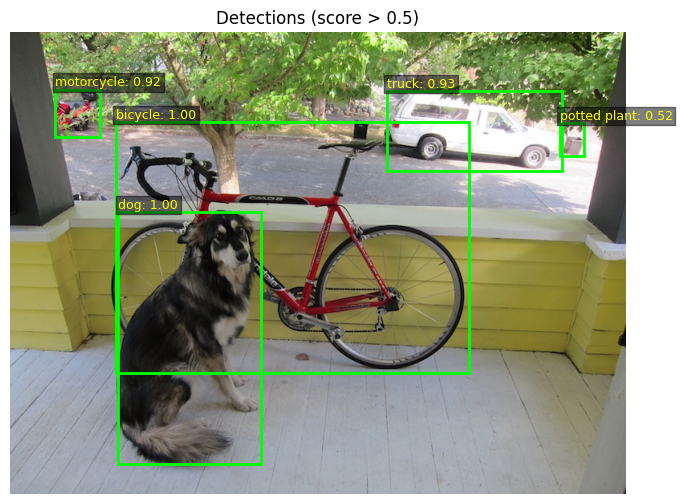

Running detection on image2


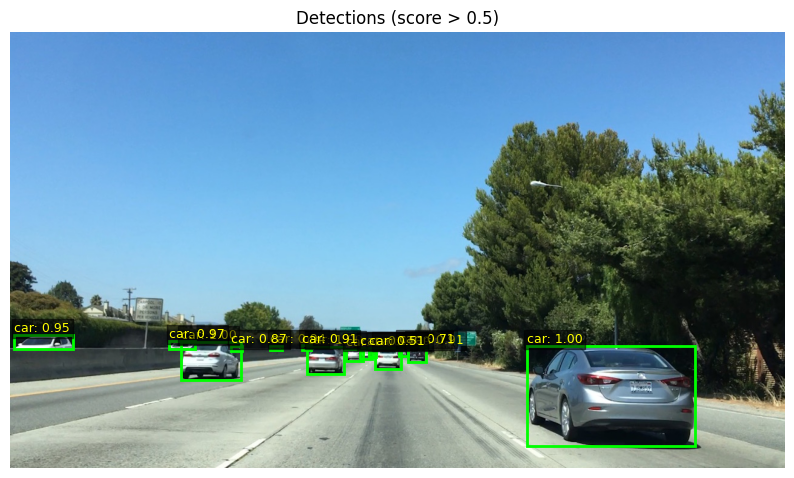

In [4]:
weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
model = fasterrcnn_resnet50_fpn_v2(weights=weights)
model.eval()
model.to('cpu')  # ← crucial!

transform = weights.transforms()

def frcnn_detect(img, score_thresh: float = 0.5):
    # Apply preprocessing and forward pass
    inputs = transform(img).unsqueeze(0)
    with torch.no_grad():
        outputs = model(inputs)[0]

    boxes = outputs["boxes"]
    labels = outputs["labels"]
    scores = outputs["scores"]

    keep = scores > score_thresh
    boxes, labels, scores = boxes[keep], labels[keep], scores[keep]

    _, ax = plt.subplots(1, 1, figsize=(10, 6))
    ax.imshow(img)
    ax.axis("off")
    if boxes.numel() == 0:
        ax.set_title("No detections above threshold")
        plt.show()
        return

    for box, label, score in zip(boxes, labels, scores):
        x1, y1, x2, y2 = box.tolist()
        rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                 linewidth=2, edgecolor='lime', facecolor='none')
        ax.add_patch(rect)
        cls_name = weights.meta["categories"][int(label)]
        ax.text(x1, max(y1 - 5, 5), f"{cls_name}: {score:.2f}",
                fontsize=9, color='yellow', bbox=dict(facecolor='black', alpha=0.5, pad=2))
    ax.set_title(f"Detections (score > {score_thresh})")
    plt.show()

# Feed Image1 and Image2 to the model and evaluate it
image_paths = [Path('Images') / 'image1.jpg', Path('Images') / 'image2.jpg']
for p in image_paths:
    print(f"Running detection on {p.name[:-4]}")
    frcnn_detect(Image.open(p).convert('RGB'))

<font size=7 color="#5499C7">Object Detection Results Analysis</font>

<font size=6 color="#5499C7">Performance Assessment</font>
<font size=5>

Faster R-CNN with FPN successfully identifies and localizes multiple objects simultaneously. The 0.5 score threshold provides a good balance between precision and recall, filtering out low-confidence false positives.
</font>

<font size=6 color="#5499C7">Detailed Analysis</font>
<font size=5>

*   **Image 1:** The model achieved perfect confidence (**1.00**) for the primary subjects: the **Dog** and the **Bicycle**. It also successfully detected background elements, identifying the white vehicle as a **Truck** (0.93) and spotting a **Potted plant** (0.52). Interestingly, it classified the red object on the porch as a **Motorcycle** (0.92).
*   **Image 2:** The model demonstrated excellent scale invariance, detecting multiple **Cars** ranging from the immediate foreground (1.00 confidence) to small vehicles deep in the background (0.51-0.97 confidence). The Non-Maximum Suppression (NMS) effectively prevented multiple bounding boxes for the same vehicle.
</font>

<font size=6 color="#5499C7">Strengths & Weaknesses</font>
<font size=5>

*   **Strengths:** Multi-object capability; accurate localization; scale invariance (detects both near and far objects).
*   **Weaknesses:** Small objects (< 30x30 pixels) are often missed or misclassified due to limited feature representation at lower resolutions.
</font>

<font size=7 color="#5499C7">4. Task 3 – Semantic Segmentation</font>

<font size=5>
In this task, we used the pretrained <b>DeepLabV3+ with ResNet50 backbone</b> model.
</font>

<font size=6 color="#5499C7">Model Architecture: DeepLabV3+</font>
<font size=5>

**DeepLabV3+** is an advanced semantic segmentation architecture that combines encoder-decoder structure with atrous convolutions.

*   **Atrous Convolutions:** Expand receptive field without losing resolution, capturing wider context.
*   **ASPP (Atrous Spatial Pyramid Pooling):** Captures multi-scale context using parallel dilated convolutions.
*   **Training Dataset:** COCO with VOC Label Mapping (21 classes).
*   **Output:** Dense pixel-wise predictions (mask) for each of the 21 PASCAL VOC categories.
</font>

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to C:\Users\Kasra/.cache\torch\hub\checkpoints\deeplabv3_resnet50_coco-cd0a2569.pth
100%|██████████| 161M/161M [00:28<00:00, 5.95MB/s] 


Segmenting image2


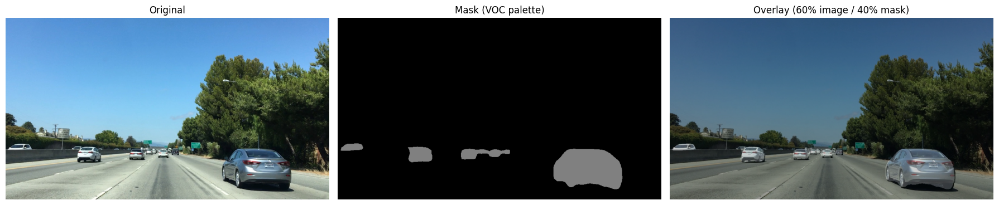

Segmenting image3


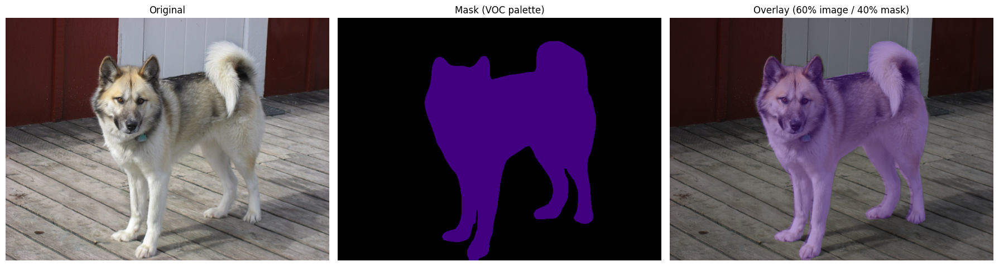

Segmenting image6


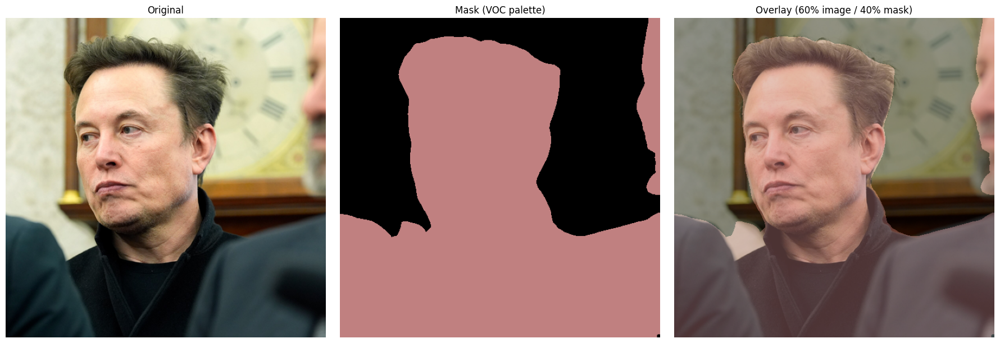

In [5]:
seg_weights = DeepLabV3_ResNet50_Weights.COCO_WITH_VOC_LABELS_V1
seg_model = deeplabv3_resnet50(weights=seg_weights)
seg_model.eval()
seg_model.to(device)

seg_preprocess = seg_weights.transforms()

# PASCAL VOC colors (21 classes)
VOC_COLORS = np.array([
    [0, 0, 0],      # background
    [128, 0, 0],    # aeroplane
    [0, 128, 0],    # bicycle
    [128, 128, 0],  # bird
    [0, 0, 128],    # boat
    [128, 0, 128],  # bottle
    [0, 128, 128],  # bus
    [128, 128, 128],# car
    [64, 0, 0],     # cat
    [192, 0, 0],    # chair
    [64, 128, 0],   # cow
    [192, 128, 0],  # dining table
    [64, 0, 128],   # dog
    [192, 0, 128],  # horse
    [64, 128, 128], # motorbike
    [192, 128, 128],# person
    [0, 64, 0],     # potted plant
    [128, 64, 0],   # sheep
    [0, 192, 0],    # sofa
    [128, 192, 0],  # train
    [0, 192, 128]   # tv/monitor
])

def segment_image(img):
    input_tensor = seg_preprocess(img).unsqueeze(0).to(device)
    with torch.no_grad():
        output = seg_model(input_tensor)['out'][0]
    pred = output.argmax(0).cpu().numpy()

    # Create colored mask
    colored_mask = VOC_COLORS[pred]
    mask_img = Image.fromarray(colored_mask.astype(np.uint8))

    # Overlay
    base = img.convert("RGB").resize(mask_img.size)
    overlay = Image.blend(base, mask_img, alpha=0.4)

    # Plot the orginal image and preprocessed version.
    _, axes = plt.subplots(1, 3, figsize=(18, 6))
    axes[0].imshow(base)
    axes[0].set_title("Original")
    axes[0].axis("off")

    axes[1].imshow(mask_img)
    axes[1].set_title("Mask (VOC palette)")
    axes[1].axis("off")

    axes[2].imshow(overlay)
    axes[2].set_title("Overlay (60% image / 40% mask)")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

    return pred

# Evaluate the model on Image2, Image3, and Image6
for fname in ['image2.jpg', 'image3.jpg', 'image6.jpg']:
    path = Path('Images') / fname
    print(f"Segmenting {fname[:-4]}")
    segment_image(Image.open(path).convert('RGB'))

<font size=7 color="#5499C7">Semantic Segmentation Results Analysis</font>

<font size=6 color="#5499C7">Performance Assessment</font>
<font size=5>

DeepLabV3+ effectively separates foreground objects from backgrounds and handles complex shapes. The model generates dense pixel-wise classifications.
</font>

<font size=6 color="#5499C7">Detailed Analysis</font>
<font size=5>

*   **Image 2:** Excellent separation of sky, road, and cars. Overlapping cars may merge into a single blob if they share the same class.
*   **Image 3:** High precision on the dog boundary due to its large scale.
*   **Image 6:** Successfully assigns different colors to different semantic categories (e.g., person vs. clock).
</font>

<font size=6 color="#5499C7">Comparison with Detection</font>
<font size=5>

*   **Segmentation:** Gives masks (shape + what). Better for applications needing area or drivable space.
*   **Detection:** Gives boxes (where + what). Better for counting distinct instances.
</font>